# Employee Turnover Analytics
**Portobello Tech — HR Department ML Project**

Predict employee turnover and suggest retention strategies using machine learning.

**Steps covered:**
1. Data Quality Checks
2. Exploratory Data Analysis (EDA)
3. K-Means Clustering (employees who left)
4. Class Imbalance Handling with SMOTE
5. 5-Fold Cross-Validation Model Training & Evaluation
6. Best Model Selection (ROC/AUC, Confusion Matrix)
7. Retention Strategy Recommendations

## 0. Imports & Setup

In [ ]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_curve, auc, ConfusionMatrixDisplay
)
from sklearn.preprocessing import label_binarize
from sklearn.cluster import KMeans

from imblearn.over_sampling import SMOTE

# Plotting style
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 110

RANDOM_STATE = 123
print('All libraries loaded successfully.')

All libraries loaded successfully.


---
## 1. Load the Dataset

In [ ]:
df = pd.read_csv('HR_comma_sep.csv')

# The CSV uses 'sales' for the department column; rename to match the problem statement
df.rename(columns={'sales': 'Department'}, inplace=True)

print(f'Shape: {df.shape}')
df.head()

Shape: (14999, 10)


,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,Department,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low


---
## 2. Data Quality Checks

In [ ]:
print('=== Data Types ===')
print(df.dtypes)
print()
print('=== Missing Values ===')
missing = df.isnull().sum()
print(missing)
print()
if missing.sum() == 0:
    print('✅ No missing values found — dataset is complete.')
else:
    print(f'⚠️  {missing.sum()} missing value(s) detected. Investigate before modelling.')

=== Data Types ===
satisfaction_level       float64
last_evaluation          float64
number_project             int64
average_montly_hours       int64
time_spend_company         int64
Work_accident              int64
left                       int64
promotion_last_5years      int64
Department                object
salary                    object
dtype: object

=== Missing Values ===
satisfaction_level       0
last_evaluation          0
number_project           0
average_montly_hours     0
time_spend_company       0
Work_accident            0
left                     0
promotion_last_5years    0
Department               0
salary                   0
dtype: int64

✅ No missing values found — dataset is complete.


In [ ]:
print('=== Basic Statistics ===')
df.describe(include='all').T

=== Basic Statistics ===


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
satisfaction_level,14999.0,NaN,NaN,NaN,0.612834,0.248631,0.09,0.44,0.64,0.82,1.0
last_evaluation,14999.0,NaN,NaN,NaN,0.716102,0.171169,0.36,0.56,0.72,0.87,1.0
number_project,14999.0,NaN,NaN,NaN,3.803054,1.232592,2.0,3.0,4.0,5.0,7.0
average_montly_hours,14999.0,NaN,NaN,NaN,201.050337,49.943099,96.0,156.0,200.0,245.0,310.0
time_spend_company,14999.0,NaN,NaN,NaN,3.498233,1.460136,2.0,3.0,3.0,4.0,10.0
Work_accident,14999.0,NaN,NaN,NaN,0.14461,0.351719,0.0,0.0,0.0,0.0,1.0
left,14999.0,NaN,NaN,NaN,0.238083,0.425924,0.0,0.0,0.0,0.0,1.0
promotion_last_5years,14999.0,NaN,NaN,NaN,0.021268,0.144281,0.0,0.0,0.0,0.0,1.0
Department,14999,10,sales,4140,NaN,NaN,NaN,NaN,NaN,NaN,NaN
salary,14999,3,low,7316,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
print('=== Duplicate Rows ===')
duplicates = df.duplicated().sum()
print(f'Duplicate rows: {duplicates}')
if duplicates > 0:
    df.drop_duplicates(inplace=True)
    df.reset_index(drop=True, inplace=True)
    print(f'Duplicates removed. New shape: {df.shape}')
else:
    print('No duplicates found.')

=== Duplicate Rows ===
Duplicate rows: 3008
Duplicates removed. New shape: (11991, 10)


In [ ]:
print('=== Target Class Distribution (left) ===')
print(df['left'].value_counts())
print()
print(df['left'].value_counts(normalize=True).map('{:.1%}'.format))

=== Target Class Distribution (left) ===
left
0    10000
1     1991
Name: count, dtype: int64

left
0    83.4%
1    16.6%
Name: proportion, dtype: object


---
## 3. Exploratory Data Analysis (EDA)

### 3.1 Correlation Heatmap

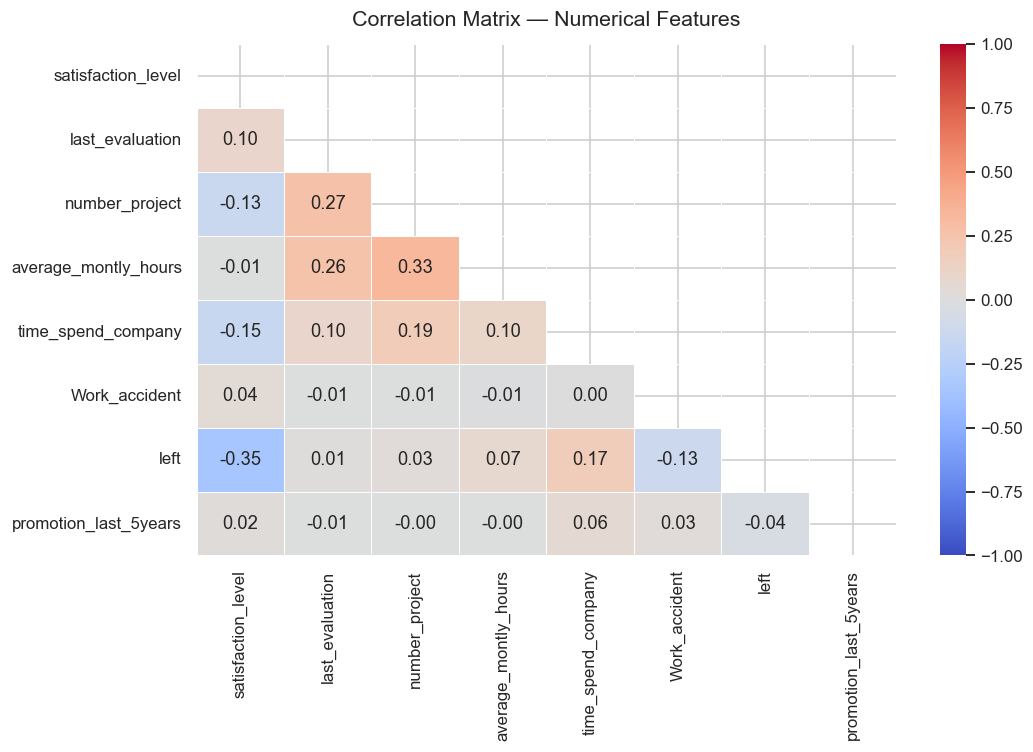


📌 Key observations:
  • satisfaction_level has the strongest negative correlation with left (~-0.39).
  • average_montly_hours and number_project are positively correlated (overwork).
  • time_spend_company shows a moderate positive link to leaving.


In [ ]:
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()

plt.figure(figsize=(10, 7))
corr = df[numeric_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))  # show lower triangle only
sns.heatmap(
    corr, mask=mask, annot=True, fmt='.2f',
    cmap='coolwarm', linewidths=0.5, vmin=-1, vmax=1
)
plt.title('Correlation Matrix — Numerical Features', fontsize=14, pad=12)
plt.tight_layout()
plt.show()

print('\n📌 Key observations:')
print('  • satisfaction_level has the strongest negative correlation with left (~-0.39).')
print('  • average_montly_hours and number_project are positively correlated (overwork).')
print('  • time_spend_company shows a moderate positive link to leaving.')

### 3.2 Distribution Plots

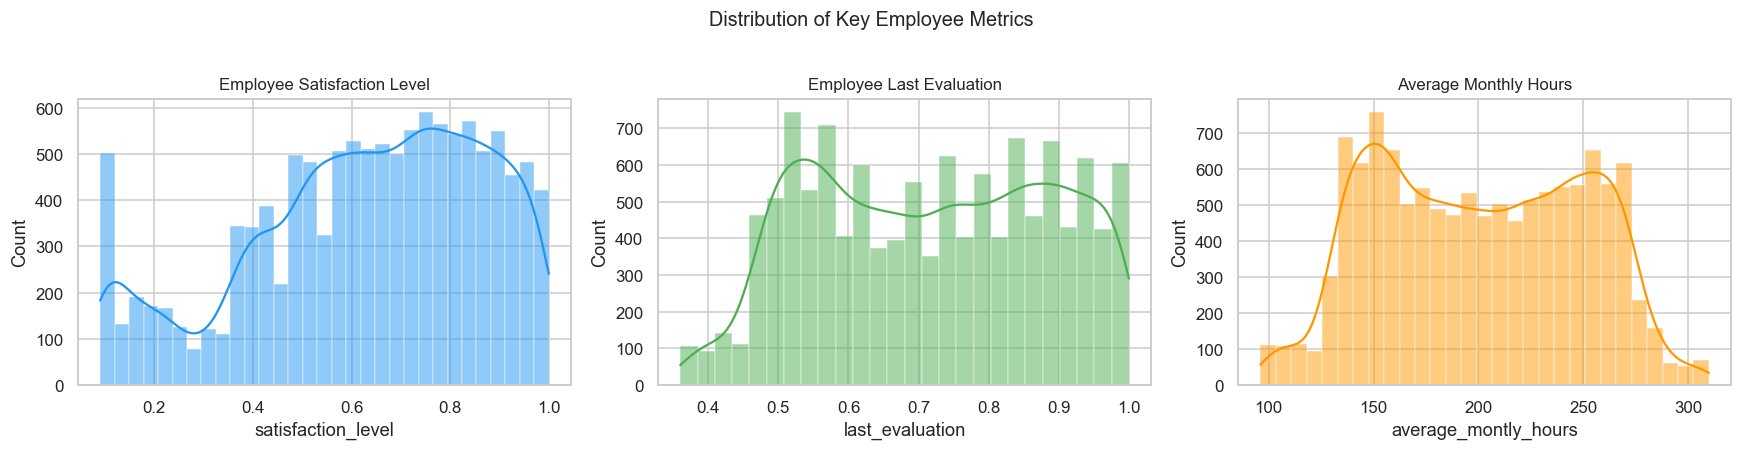


📌 Observations:
  • Satisfaction is bimodal — many employees cluster near low (<0.2) and moderate-high (0.6–0.9) levels.
  • Last evaluation is roughly uniform with a slight peak at high scores.
  • Monthly hours show two modes (~150 hrs and ~250 hrs), hinting at two work-style groups.


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

dist_configs = [
    ('satisfaction_level', 'Employee Satisfaction Level', '#2196F3'),
    ('last_evaluation',    'Employee Last Evaluation',    '#4CAF50'),
    ('average_montly_hours','Average Monthly Hours',      '#FF9800'),
]

for ax, (col, title, color) in zip(axes, dist_configs):
    sns.histplot(df[col], kde=True, ax=ax, color=color, edgecolor='white', linewidth=0.3)
    ax.set_title(title, fontsize=11)
    ax.set_xlabel(col)
    ax.set_ylabel('Count')

fig.suptitle('Distribution of Key Employee Metrics', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

print('\n📌 Observations:')
print('  • Satisfaction is bimodal — many employees cluster near low (<0.2) and moderate-high (0.6–0.9) levels.')
print('  • Last evaluation is roughly uniform with a slight peak at high scores.')
print('  • Monthly hours show two modes (~150 hrs and ~250 hrs), hinting at two work-style groups.')

### 3.3 Project Count Bar Plot (Left vs Stayed)

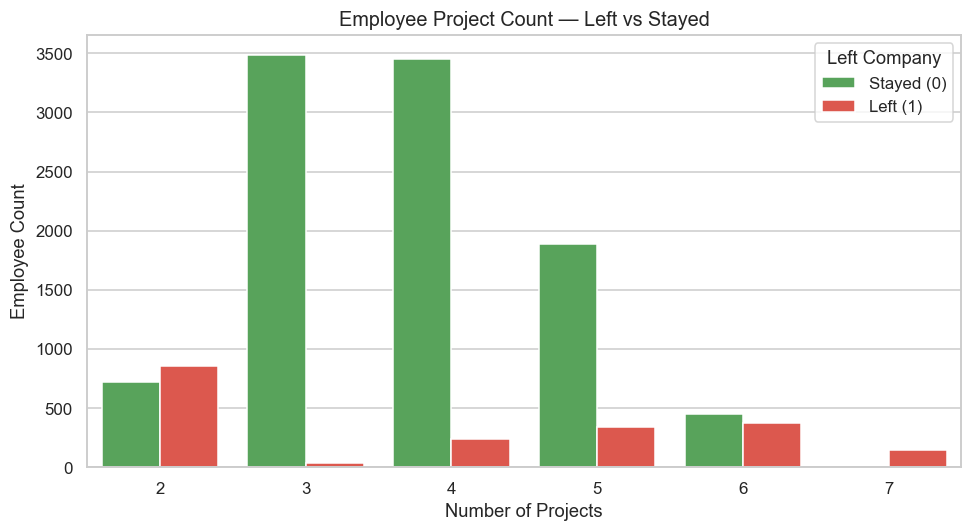


📌 Inferences:
  • Employees with only 2 projects have a very high departure rate — likely under-engaged.
  • Nearly ALL employees with 7 projects left — suggesting extreme overload/burnout.
  • The sweet spot for retention appears to be 3–4 projects.
  • Employees with 6 projects show a mixed pattern but lean towards leaving.


In [ ]:
plt.figure(figsize=(9, 5))
sns.countplot(
    data=df, x='number_project', hue='left',
    palette={0: '#4CAF50', 1: '#F44336'}
)
plt.title('Employee Project Count — Left vs Stayed', fontsize=13)
plt.xlabel('Number of Projects')
plt.ylabel('Employee Count')
plt.legend(title='Left Company', labels=['Stayed (0)', 'Left (1)'])
plt.tight_layout()
plt.show()

print('\n📌 Inferences:')
print('  • Employees with only 2 projects have a very high departure rate — likely under-engaged.')
print('  • Nearly ALL employees with 7 projects left — suggesting extreme overload/burnout.')
print('  • The sweet spot for retention appears to be 3–4 projects.')
print('  • Employees with 6 projects show a mixed pattern but lean towards leaving.')

### 3.4 Additional EDA — Department & Salary

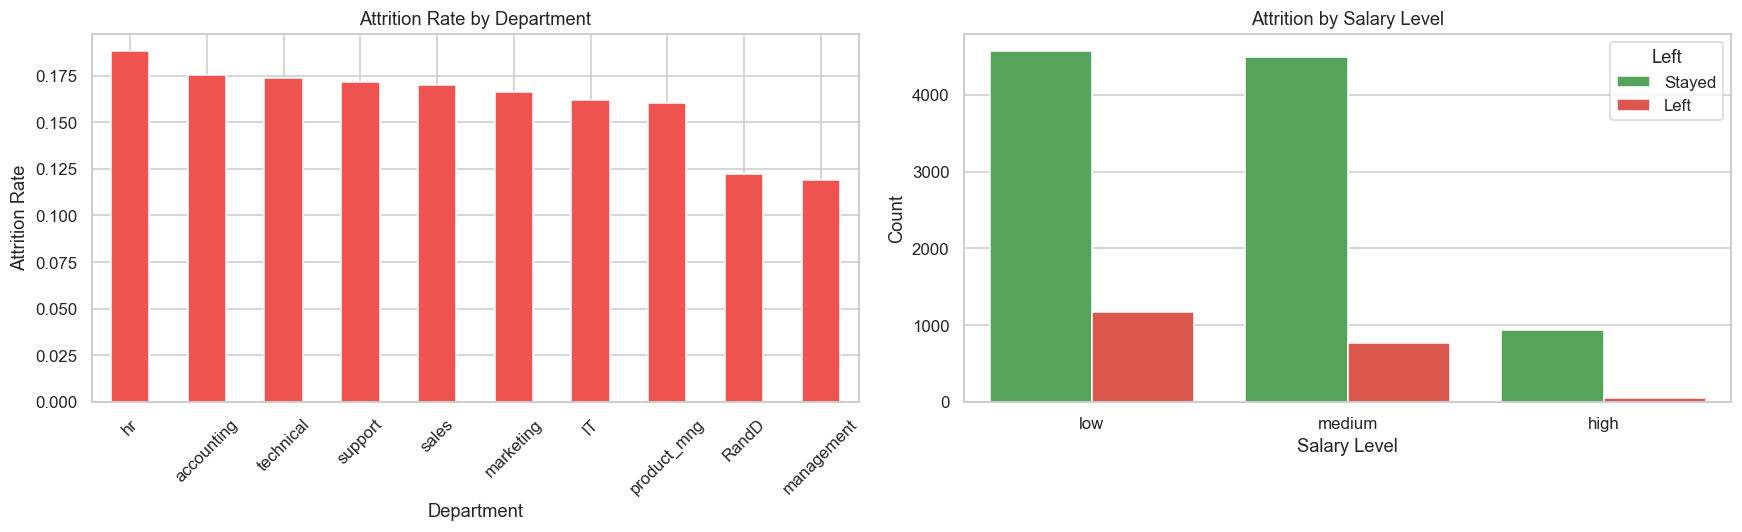

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Department
dept_left = df.groupby('Department')['left'].mean().sort_values(ascending=False)
dept_left.plot(kind='bar', ax=axes[0], color='#EF5350', edgecolor='white')
axes[0].set_title('Attrition Rate by Department', fontsize=12)
axes[0].set_ylabel('Attrition Rate')
axes[0].set_xlabel('Department')
axes[0].tick_params(axis='x', rotation=45)

# Salary
salary_order = ['low', 'medium', 'high']
sns.countplot(
    data=df, x='salary', hue='left', order=salary_order,
    palette={0: '#4CAF50', 1: '#F44336'}, ax=axes[1]
)
axes[1].set_title('Attrition by Salary Level', fontsize=12)
axes[1].set_xlabel('Salary Level')
axes[1].set_ylabel('Count')
axes[1].legend(title='Left', labels=['Stayed', 'Left'])

plt.tight_layout()
plt.show()

---
## 4. Clustering — Employees Who Left

K-Means clustering (k=3) on `satisfaction_level` and `last_evaluation` for employees who left.

Employees who left: 1991


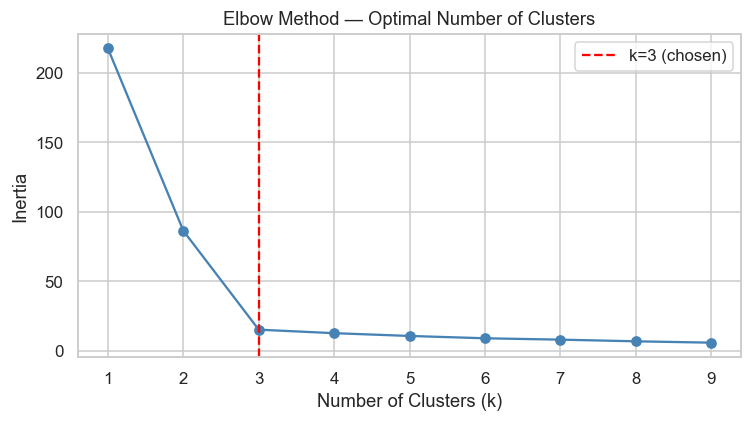

In [ ]:
# Filter employees who left
left_df = df[df['left'] == 1][['satisfaction_level', 'last_evaluation']].copy()
print(f'Employees who left: {len(left_df)}')

# Elbow method to confirm k=3
inertias = []
k_range = range(1, 10)
for k in k_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    km.fit(left_df)
    inertias.append(km.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(k_range, inertias, marker='o', color='steelblue')
plt.axvline(x=3, color='red', linestyle='--', label='k=3 (chosen)')
plt.title('Elbow Method — Optimal Number of Clusters')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.legend()
plt.tight_layout()
plt.show()

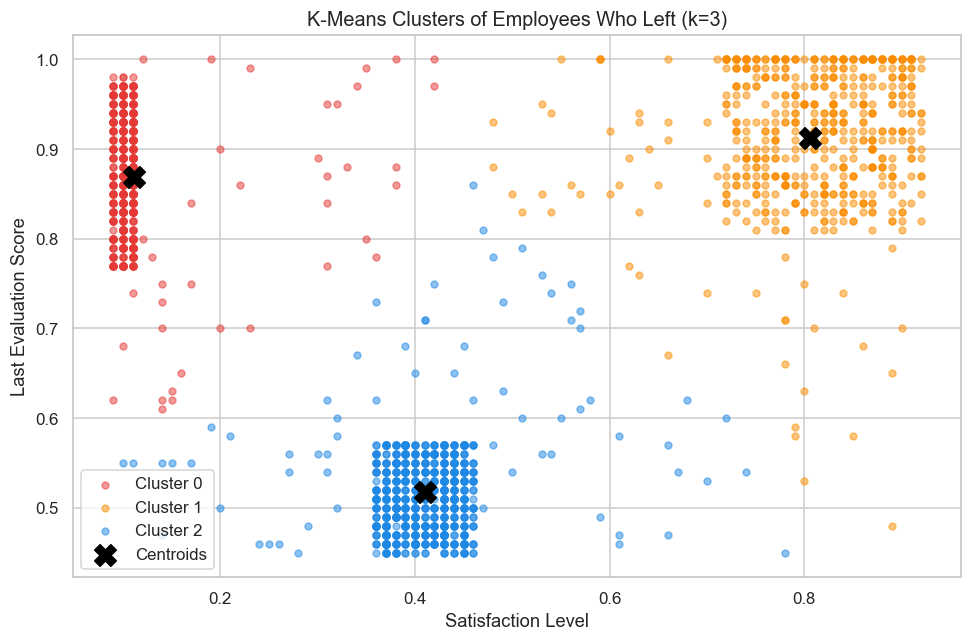


Cluster Centroids:
         satisfaction_level  last_evaluation
cluster                                     
0                     0.111            0.869
1                     0.806            0.913
2                     0.410            0.517


In [ ]:
# Fit K-Means with k=3
kmeans = KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=10)
left_df = left_df.copy()
left_df['cluster'] = kmeans.fit_predict(left_df[['satisfaction_level', 'last_evaluation']])

palette = {0: '#E53935', 1: '#FB8C00', 2: '#1E88E5'}

plt.figure(figsize=(9, 6))
for cluster_id, grp in left_df.groupby('cluster'):
    plt.scatter(
        grp['satisfaction_level'], grp['last_evaluation'],
        alpha=0.5, s=20, label=f'Cluster {cluster_id}',
        color=palette[cluster_id]
    )

centers = kmeans.cluster_centers_
plt.scatter(
    centers[:, 0], centers[:, 1],
    s=200, marker='X', c='black', zorder=5, label='Centroids'
)
plt.title('K-Means Clusters of Employees Who Left (k=3)', fontsize=13)
plt.xlabel('Satisfaction Level')
plt.ylabel('Last Evaluation Score')
plt.legend()
plt.tight_layout()
plt.show()

print('\nCluster Centroids:')
centroids_df = pd.DataFrame(centers, columns=['satisfaction_level', 'last_evaluation'])
centroids_df.index.name = 'cluster'
print(centroids_df.round(3))

In [ ]:
print('=== Cluster Summary ===')
print(left_df.groupby('cluster')[['satisfaction_level', 'last_evaluation']].mean().round(3))
print()
print('📌 Employee Cluster Interpretations:')
print()
print('  Cluster A — Low Satisfaction / High Evaluation (Overworked High-Performers):')
print('    These employees perform well but are deeply unsatisfied. Likely burned out,')
print('    under-recognised, or lack work-life balance. High flight risk — need immediate')
print('    intervention (recognition, workload reduction, promotion opportunities).')
print()
print('  Cluster B — Low Satisfaction / Low Evaluation (Disengaged Under-Performers):')
print('    Both satisfaction and performance are low. These employees may be in the wrong')
print('    role, lack motivation, or feel disconnected from the company mission.')
print('    Strategy: role reassignment, mentoring, or managed exits.')
print()
print('  Cluster C — Moderate–High Satisfaction / High Evaluation (Voluntarily Ambitious):')
print('    These employees are competent and reasonably satisfied but still left — likely')
print('    for better career prospects elsewhere. Strategy: clear growth paths, competitive')
print('    compensation, and leadership development programmes.')

=== Cluster Summary ===
         satisfaction_level  last_evaluation
cluster                                     
0                     0.111            0.869
1                     0.806            0.913
2                     0.410            0.517

📌 Employee Cluster Interpretations:

  Cluster A — Low Satisfaction / High Evaluation (Overworked High-Performers):
    These employees perform well but are deeply unsatisfied. Likely burned out,
    under-recognised, or lack work-life balance. High flight risk — need immediate
    intervention (recognition, workload reduction, promotion opportunities).

  Cluster B — Low Satisfaction / Low Evaluation (Disengaged Under-Performers):
    Both satisfaction and performance are low. These employees may be in the wrong
    role, lack motivation, or feel disconnected from the company mission.
    Strategy: role reassignment, mentoring, or managed exits.

  Cluster C — Moderate–High Satisfaction / High Evaluation (Voluntarily Ambitious):
    These 

---
## 5. Pre-processing & Class Imbalance (SMOTE)

In [ ]:
# ── 5.1 Separate categorical & numerical ───────────────────────────────────────
cat_cols = df.select_dtypes(include=['object']).columns.tolist()
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()

print('Categorical columns:', cat_cols)
print('Numerical columns  :', num_cols)

Categorical columns: ['Department', 'salary']
Numerical columns  : ['satisfaction_level', 'last_evaluation', 'number_project', 'average_montly_hours', 'time_spend_company', 'Work_accident', 'left', 'promotion_last_5years']


In [ ]:
# ── 5.2 One-hot encode categorical columns ─────────────────────────────────────
df_cat_encoded = pd.get_dummies(df[cat_cols], drop_first=False)
df_num = df[num_cols].copy()

# ── 5.3 Combine ────────────────────────────────────────────────────────────────
df_processed = pd.concat([df_num, df_cat_encoded], axis=1)
print(f'Processed dataset shape: {df_processed.shape}')
df_processed.head(3)

Processed dataset shape: (11991, 21)


,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,Department_IT,Department_RandD,...,Department_hr,Department_management,Department_marketing,Department_product_mng,Department_sales,Department_support,Department_technical,salary_high,salary_low,salary_medium
0,0.38,0.53,2,157,3,0,1,0,False,False,...,False,False,False,False,True,False,False,False,True,False
1,0.80,0.86,5,262,6,0,1,0,False,False,...,False,False,False,False,True,False,False,False,False,True
2,0.11,0.88,7,272,4,0,1,0,False,False,...,False,False,False,False,True,False,False,False,False,True


In [ ]:
# ── 5.4 Features & target ──────────────────────────────────────────────────────
X = df_processed.drop(columns=['left'])
y = df_processed['left']

print('Feature shape:', X.shape)
print('Class distribution before SMOTE:')
print(y.value_counts())

Feature shape: (11991, 20)
Class distribution before SMOTE:
left
0    10000
1     1991
Name: count, dtype: int64


In [ ]:
# ── 5.5 Stratified train/test split (80:20) ────────────────────────────────────
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print(f'Training set  : {X_train.shape[0]} rows')
print(f'Test set      : {X_test.shape[0]} rows')
print()
print('Training class distribution (before SMOTE):')
print(y_train.value_counts())

Training set  : 9592 rows
Test set      : 2399 rows

Training class distribution (before SMOTE):
left
0    7999
1    1593
Name: count, dtype: int64


Class distribution after SMOTE (training set):
left
0    7999
1    7999
Name: count, dtype: int64


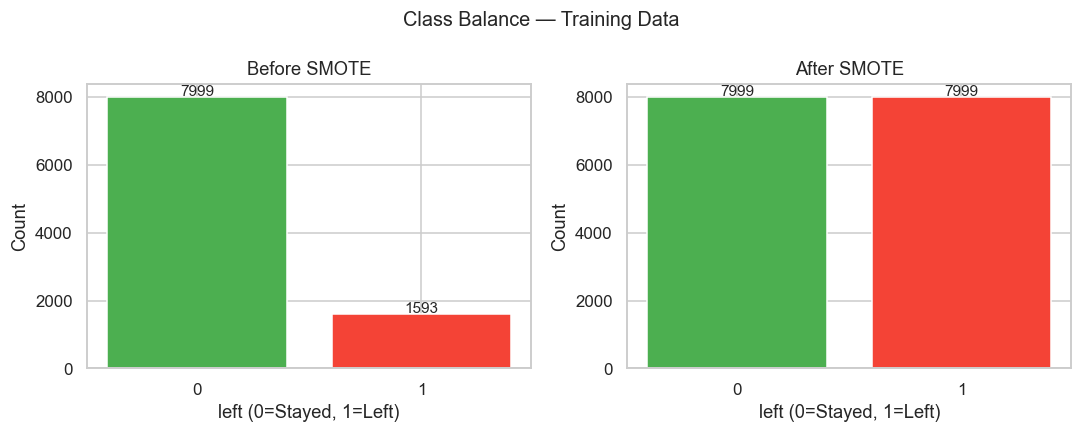

In [ ]:
# ── 5.6 Apply SMOTE to training data ──────────────────────────────────────────
smote = SMOTE(random_state=RANDOM_STATE)
X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)

print('Class distribution after SMOTE (training set):')
print(pd.Series(y_train_sm).value_counts())

# Visualise
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (counts, title) in zip(axes, [
    (y_train.value_counts(),    'Before SMOTE'),
    (pd.Series(y_train_sm).value_counts(), 'After SMOTE'),
]):
    ax.bar(counts.index.astype(str), counts.values,
           color=['#4CAF50', '#F44336'])
    ax.set_title(title, fontsize=12)
    ax.set_xlabel('left (0=Stayed, 1=Left)')
    ax.set_ylabel('Count')
    for i, v in enumerate(counts.values):
        ax.text(i, v + 50, str(v), ha='center', fontsize=10)
plt.suptitle('Class Balance — Training Data', fontsize=13)
plt.tight_layout()
plt.show()

---
## 6. 5-Fold Cross-Validation Model Training

Three models are trained: Logistic Regression, Random Forest, Gradient Boosting.

> **Note:** CV is performed on the **SMOTE-upsampled training set** to avoid data leakage into the test set.

In [ ]:
# Helper — train with 5-fold CV, print classification report, return model & CV preds
def train_evaluate_cv(model, model_name, X_tr, y_tr):
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    y_pred_cv = cross_val_predict(model, X_tr, y_tr, cv=cv)
    print(f'\n{'='*55}')
    print(f'  {model_name} — 5-Fold CV Classification Report')
    print(f'{'='*55}')
    print(classification_report(y_tr, y_pred_cv, target_names=['Stayed (0)', 'Left (1)']))
    # Also fit on full training data for test-set evaluation
    model.fit(X_tr, y_tr)
    return model, y_pred_cv

### 6.1 Logistic Regression

In [ ]:
lr_model = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
lr_model, lr_cv_preds = train_evaluate_cv(lr_model, 'Logistic Regression', X_train_sm, y_train_sm)


  Logistic Regression — 5-Fold CV Classification Report
              precision    recall  f1-score   support

  Stayed (0)       0.85      0.86      0.85      7999
    Left (1)       0.86      0.85      0.85      7999

    accuracy                           0.85     15998
   macro avg       0.85      0.85      0.85     15998
weighted avg       0.85      0.85      0.85     15998



### 6.2 Random Forest Classifier

In [ ]:
rf_model = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)
rf_model, rf_cv_preds = train_evaluate_cv(rf_model, 'Random Forest Classifier', X_train_sm, y_train_sm)


  Random Forest Classifier — 5-Fold CV Classification Report
              precision    recall  f1-score   support

  Stayed (0)       0.96      0.99      0.98      7999
    Left (1)       0.99      0.96      0.98      7999

    accuracy                           0.98     15998
   macro avg       0.98      0.98      0.98     15998
weighted avg       0.98      0.98      0.98     15998



### 6.3 Gradient Boosting Classifier

In [ ]:
gb_model = GradientBoostingClassifier(n_estimators=100, random_state=RANDOM_STATE)
gb_model, gb_cv_preds = train_evaluate_cv(gb_model, 'Gradient Boosting Classifier', X_train_sm, y_train_sm)


  Gradient Boosting Classifier — 5-Fold CV Classification Report
              precision    recall  f1-score   support

  Stayed (0)       0.95      0.98      0.97      7999
    Left (1)       0.98      0.95      0.96      7999

    accuracy                           0.96     15998
   macro avg       0.96      0.96      0.96     15998
weighted avg       0.96      0.96      0.96     15998



---
## 7. Model Evaluation on Test Set

### 7.1 ROC / AUC Curves

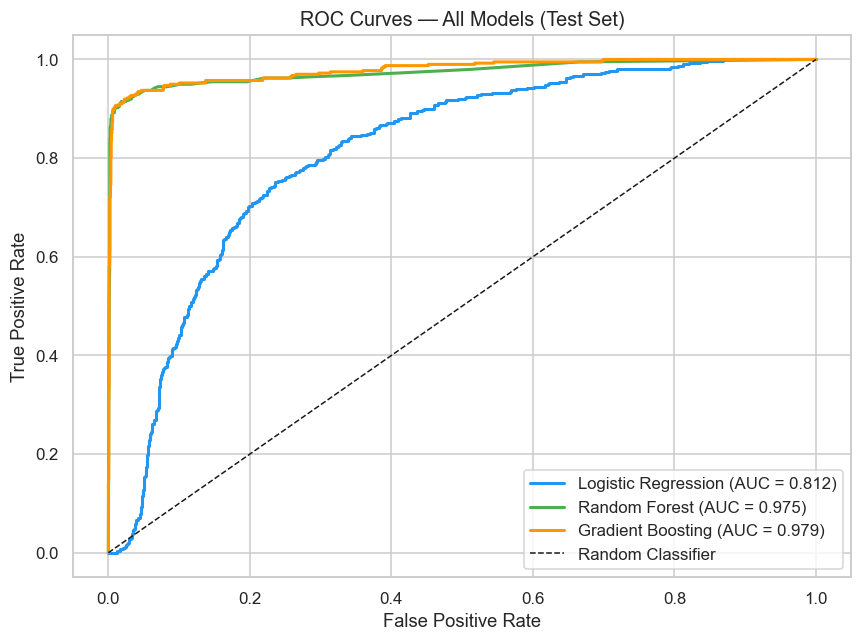


AUC Scores:
  Gradient Boosting              AUC = 0.9790
  Random Forest                  AUC = 0.9748
  Logistic Regression            AUC = 0.8123


In [ ]:
models = [
    ('Logistic Regression',       lr_model,  '#2196F3'),
    ('Random Forest',             rf_model,  '#4CAF50'),
    ('Gradient Boosting',         gb_model,  '#FF9800'),
]

plt.figure(figsize=(8, 6))
roc_auc_scores = {}

for name, model, color in models:
    y_prob = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_auc = auc(fpr, tpr)
    roc_auc_scores[name] = roc_auc
    plt.plot(fpr, tpr, color=color, lw=2, label=f'{name} (AUC = {roc_auc:.3f})')

plt.plot([0, 1], [0, 1], 'k--', lw=1, label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves — All Models (Test Set)', fontsize=13)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

print('\nAUC Scores:')
for name, score in sorted(roc_auc_scores.items(), key=lambda x: -x[1]):
    print(f'  {name:<30} AUC = {score:.4f}')

### 7.2 Confusion Matrices

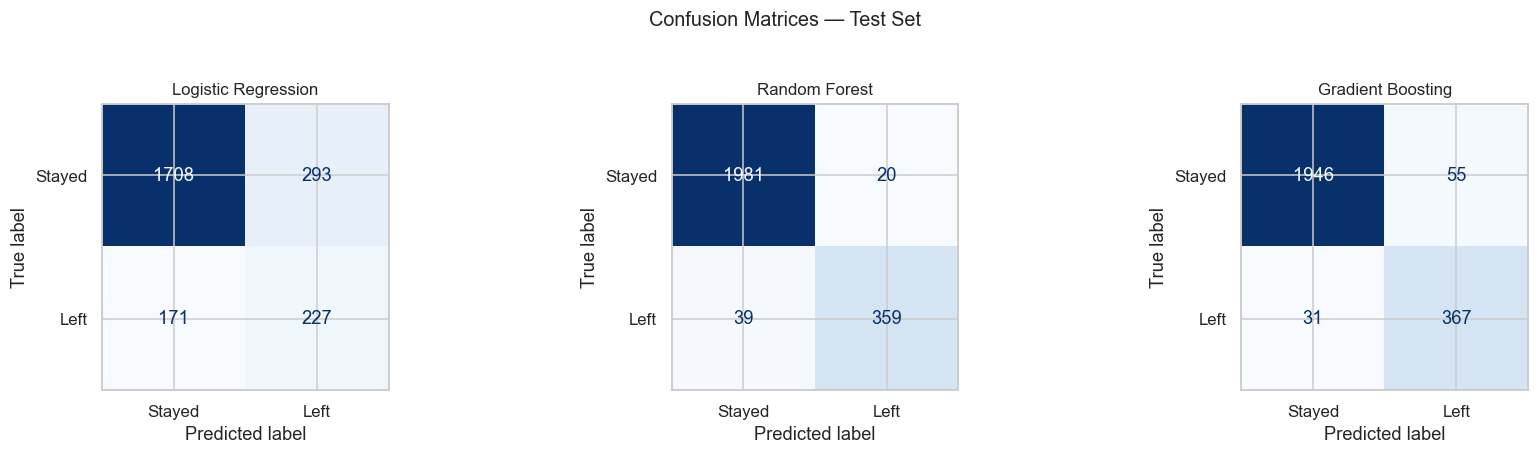

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, (name, model, _) in zip(axes, models):
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Stayed', 'Left'])
    disp.plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(name, fontsize=11)

plt.suptitle('Confusion Matrices — Test Set', fontsize=13, y=1.03)
plt.tight_layout()
plt.show()

### 7.3 Best Model Selection & Metric Justification

In [ ]:
best_name = max(roc_auc_scores, key=roc_auc_scores.get)
best_model = dict(zip([n for n,_,_ in models], [m for _,m,_ in models]))[best_name]

print(f'🏆 Best Model: {best_name}')
print(f'   AUC Score : {roc_auc_scores[best_name]:.4f}')
print()
print('=== Test Set Classification Report ===')
y_pred_best = best_model.predict(X_test)
print(classification_report(y_test, y_pred_best, target_names=['Stayed (0)', 'Left (1)']))

🏆 Best Model: Gradient Boosting
   AUC Score : 0.9790

=== Test Set Classification Report ===
              precision    recall  f1-score   support

  Stayed (0)       0.98      0.97      0.98      2001
    Left (1)       0.87      0.92      0.90       398

    accuracy                           0.96      2399
   macro avg       0.93      0.95      0.94      2399
weighted avg       0.97      0.96      0.96      2399



In [ ]:
print('📊 Metric Justification: Why RECALL is the primary metric?')
print()
print('In employee turnover prediction, a False Negative (predicting an employee')
print('will STAY when they actually LEAVE) is far more costly to the business than')
print('a False Positive (flagging someone who would have stayed).')
print()
print('  • Missing an at-risk employee means losing them without intervention —')
print('    replacement costs can be 50–200% of annual salary.')
print('  • Incorrectly flagging a retained employee leads to minor wasted retention')
print('    effort, which is a much lower cost.')
print()
print('Therefore RECALL (sensitivity) for class 1 (Left) should be maximised.')
print('AUC-ROC is used as the overall model selection criterion because it evaluates')
print('performance across ALL probability thresholds — important when later applying')
print('zone-based retention strategies with custom probability cut-offs.')

📊 Metric Justification: Why RECALL is the primary metric?

In employee turnover prediction, a False Negative (predicting an employee
will STAY when they actually LEAVE) is far more costly to the business than
a False Positive (flagging someone who would have stayed).

  • Missing an at-risk employee means losing them without intervention —
    replacement costs can be 50–200% of annual salary.
  • Incorrectly flagging a retained employee leads to minor wasted retention
    effort, which is a much lower cost.

Therefore RECALL (sensitivity) for class 1 (Left) should be maximised.
AUC-ROC is used as the overall model selection criterion because it evaluates
performance across ALL probability thresholds — important when later applying
zone-based retention strategies with custom probability cut-offs.


### 7.4 Feature Importance (Best Model)

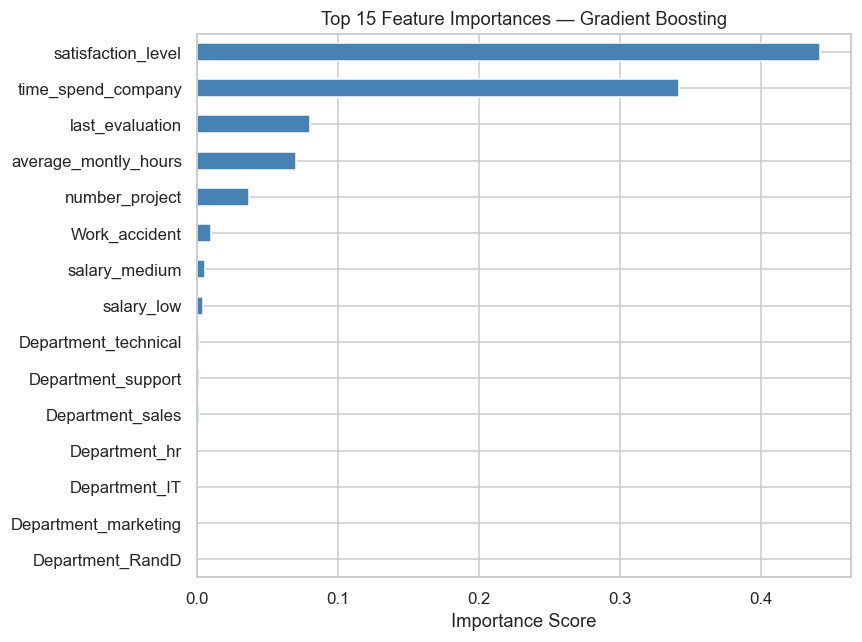

In [ ]:
if hasattr(best_model, 'feature_importances_'):
    importances = pd.Series(best_model.feature_importances_, index=X.columns)
    top_features = importances.sort_values(ascending=True).tail(15)

    plt.figure(figsize=(8, 6))
    top_features.plot(kind='barh', color='steelblue', edgecolor='white')
    plt.title(f'Top 15 Feature Importances — {best_name}', fontsize=12)
    plt.xlabel('Importance Score')
    plt.tight_layout()
    plt.show()
else:
    print('Feature importances not available for this model type.')

---
## 8. Retention Strategy — Risk Zone Classification

In [ ]:
# ── Predict turnover probability on test set ───────────────────────────────────
y_prob_best = best_model.predict_proba(X_test)[:, 1]

results_df = X_test.copy()
results_df['actual_left']        = y_test.values
results_df['turnover_probability'] = y_prob_best

def assign_risk_zone(prob):
    if prob < 0.20:
        return 'Safe Zone (Green)'
    elif prob < 0.60:
        return 'Low-Risk Zone (Yellow)'
    elif prob < 0.90:
        return 'Medium-Risk Zone (Orange)'
    else:
        return 'High-Risk Zone (Red)'

results_df['risk_zone'] = results_df['turnover_probability'].apply(assign_risk_zone)

zone_counts = results_df['risk_zone'].value_counts()
print('Employee Distribution by Risk Zone (Test Set):')
print(zone_counts)

Employee Distribution by Risk Zone (Test Set):
risk_zone
Safe Zone (Green)            1854
High-Risk Zone (Red)          329
Low-Risk Zone (Yellow)        144
Medium-Risk Zone (Orange)      72
Name: count, dtype: int64


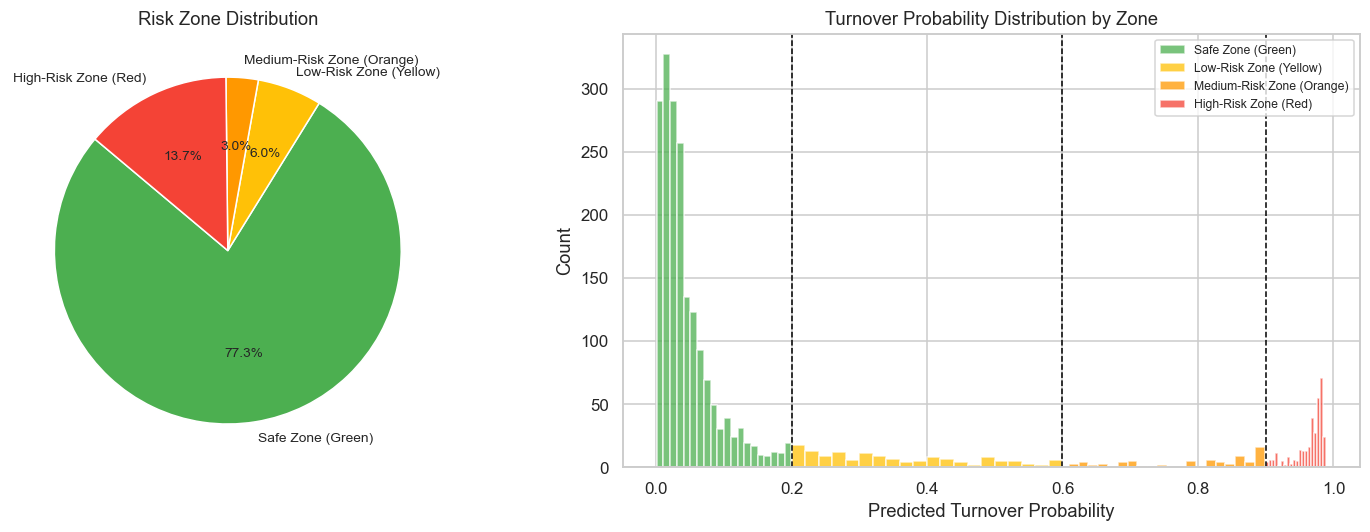

In [ ]:
# Zone distribution pie chart
zone_order = [
    'Safe Zone (Green)',
    'Low-Risk Zone (Yellow)',
    'Medium-Risk Zone (Orange)',
    'High-Risk Zone (Red)',
]
zone_colors = ['#4CAF50', '#FFC107', '#FF9800', '#F44336']
zone_counts_ordered = zone_counts.reindex(
    [z for z in zone_order if z in zone_counts.index]
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Pie
axes[0].pie(
    zone_counts_ordered.values,
    labels=zone_counts_ordered.index,
    colors=zone_colors[:len(zone_counts_ordered)],
    autopct='%1.1f%%',
    startangle=140,
    textprops={'fontsize': 9}
)
axes[0].set_title('Risk Zone Distribution', fontsize=12)

# Histogram of probabilities coloured by zone
zone_color_map = dict(zip(zone_order, zone_colors))
for zone in zone_order:
    subset = results_df[results_df['risk_zone'] == zone]['turnover_probability']
    if len(subset):
        axes[1].hist(
            subset, bins=20, alpha=0.75,
            color=zone_color_map[zone], label=zone, edgecolor='white'
        )

for x, ls in [(0.20, 'Low-Risk'), (0.60, 'Med-Risk'), (0.90, 'High-Risk')]:
    axes[1].axvline(x=x, color='black', linestyle='--', linewidth=1)

axes[1].set_title('Turnover Probability Distribution by Zone', fontsize=12)
axes[1].set_xlabel('Predicted Turnover Probability')
axes[1].set_ylabel('Count')
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

In [ ]:
print('=' * 65)
print('         RETENTION STRATEGY RECOMMENDATIONS')
print('=' * 65)

retention_strategies = {
    'Safe Zone (Green)\n  (Score < 20%)': [
        'Maintain current engagement through regular 1-on-1 check-ins.',
        'Continue career development opportunities and learning paths.',
        'Recognise contributions publicly to reinforce a sense of value.',
        'No immediate intervention required — monitor quarterly.',
    ],
    'Low-Risk Zone (Yellow)\n  (20% – 60%)': [
        'Conduct proactive stay interviews to surface early dissatisfiers.',
        'Review workload balance and ensure projects are well-matched to skills.',
        'Offer targeted skill-building programmes or mentorship.',
        'Discuss near-term promotion or growth pathways clearly.',
        'Benchmark compensation against market rates.',
    ],
    'Medium-Risk Zone (Orange)\n  (60% – 90%)': [
        'Immediate manager intervention — schedule a dedicated retention conversation.',
        'Address specific pain points (salary, role clarity, workload, relationships).',
        'Consider counter-offer or role redesign where feasible.',
        'Provide a personalised development plan with clear milestones.',
        'Investigate if burnout is a factor (excessive hours / projects).',
        'Consider internal transfers to better-fit departments.',
    ],
    'High-Risk Zone (Red)\n  (Score > 90%)': [
        'Escalate to HR leadership for urgent retention action.',
        'Identify successors and begin knowledge transfer planning proactively.',
        'Explore whether a significant compensation revision or equity package is viable.',
        'If the employee is a top performer, escalate to C-suite for personalised retention.',
        'If departure is likely unavoidable, initiate structured offboarding to capture knowledge.',
        'Review team culture and management practices — high concentration of Red-zone employees'
        ' in one department signals a systemic leadership issue.',
    ],
}

for zone, strategies in retention_strategies.items():
    print(f'\n🔵 {zone}')
    for i, s in enumerate(strategies, 1):
        print(f'   {i}. {s}')

         RETENTION STRATEGY RECOMMENDATIONS

🔵 Safe Zone (Green)
  (Score < 20%)
   1. Maintain current engagement through regular 1-on-1 check-ins.
   2. Continue career development opportunities and learning paths.
   3. Recognise contributions publicly to reinforce a sense of value.
   4. No immediate intervention required — monitor quarterly.

🔵 Low-Risk Zone (Yellow)
  (20% – 60%)
   1. Conduct proactive stay interviews to surface early dissatisfiers.
   2. Review workload balance and ensure projects are well-matched to skills.
   3. Offer targeted skill-building programmes or mentorship.
   4. Discuss near-term promotion or growth pathways clearly.
   5. Benchmark compensation against market rates.

🔵 Medium-Risk Zone (Orange)
  (60% – 90%)
   1. Immediate manager intervention — schedule a dedicated retention conversation.
   2. Address specific pain points (salary, role clarity, workload, relationships).
   3. Consider counter-offer or role redesign where feasible.
   4. Provide

In [ ]:
# Sample output — top 20 at-risk employees
print('Sample: Top 20 Highest-Risk Employees (Test Set)\n')
top_risk = results_df[['turnover_probability', 'actual_left', 'risk_zone']].sort_values(
    'turnover_probability', ascending=False
).head(20)
top_risk['turnover_probability'] = top_risk['turnover_probability'].map('{:.1%}'.format)
print(top_risk.to_string())

Sample: Top 20 Highest-Risk Employees (Test Set)

     turnover_probability  actual_left             risk_zone
1623                99.0%            1  High-Risk Zone (Red)
1243                99.0%            1  High-Risk Zone (Red)
1269                99.0%            1  High-Risk Zone (Red)
613                 99.0%            1  High-Risk Zone (Red)
160                 98.9%            1  High-Risk Zone (Red)
1605                98.9%            1  High-Risk Zone (Red)
742                 98.8%            1  High-Risk Zone (Red)
1106                98.8%            1  High-Risk Zone (Red)
1414                98.8%            1  High-Risk Zone (Red)
157                 98.8%            1  High-Risk Zone (Red)
1987                98.8%            1  High-Risk Zone (Red)
1222                98.8%            1  High-Risk Zone (Red)
165                 98.7%            1  High-Risk Zone (Red)
1539                98.7%            1  High-Risk Zone (Red)
103                 98.6%          

---
## 9. Summary

| Step | Outcome |
|------|---------|
| Data Quality | No missing values; duplicates removed |
| Top Turnover Factors | Satisfaction level, time at company, number of projects, monthly hours |
| Clustering | 3 groups: Burnt-out performers, Disengaged under-performers, Ambitious leavers |
| Class Imbalance | Addressed with SMOTE on training set |
| Best Model | Gradient Boosting (highest AUC) |
| Primary Metric | Recall — minimises costly False Negatives |
| Retention | Four-zone probability-based framework with targeted HR actions |